# Employee Attrition Prediction Models

## Project Overview

This project aims to predict whether an employee will leave an organization using Machine Learning classification algorithms.

## Objectives

- Analyze employee attrition data.
- Prepare data for machine learning.
- Build classification models.
- Compare model performance.
- Improve models through hyperparameter tuning and cross-validation.
- Identify important features affecting employee attrition.

## Algorithms

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost

## Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [1]:

# ==========================================
# EMPLOYEE ATTRITION PREDICTION
# STEP 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# ==========================================
# STEP 2: UPLOAD AND LOAD DATASET
# ==========================================

from google.colab import files
import pandas as pd
import io

# Choose CSV file from your computer
uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset uploaded successfully!")
print("File Name:", file_name)
print("Dataset Shape:", df.shape)

display(df.head())


Saving WA_Fn-UseC_-HR-Employee-Attrition 2.csv to WA_Fn-UseC_-HR-Employee-Attrition 2 (1).csv
Dataset uploaded successfully!
File Name: WA_Fn-UseC_-HR-Employee-Attrition 2 (1).csv
Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:

# ==========================================
# STEP 3: DATASET OVERVIEW
# ==========================================

print("Dataset Information:")
print("-" * 40)

print("Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)


Dataset Information:
----------------------------------------
Shape: (1470, 35)
Total Rows: 1470
Total Columns: 35

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


In [5]:

# ==========================================
# STEP 4: TARGET VARIABLE ANALYSIS
# ==========================================

print("Attrition Distribution:")
print(df["Attrition"].value_counts())

print("\nAttrition Percentage:")
print(df["Attrition"].value_counts(normalize=True) * 100)


Attrition Distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


In [6]:

# ==========================================
# STEP 5: MISSING VALUE ANALYSIS
# ==========================================

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values in Each Column:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCu

In [7]:

# ==========================================
# STEP 6: DUPLICATE RECORD ANALYSIS
# ==========================================

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicate records removed.")
else:
    print("No duplicate records found.")

print("Final Dataset Shape:", df.shape)


Total Duplicate Records: 0
No duplicate records found.
Final Dataset Shape: (1470, 35)


In [8]:

# STEP 7: OUTLIER DETECTION

numerical_df = df.select_dtypes(include=["int64", "float64"])

Q1 = numerical_df.quantile(0.25)
Q3 = numerical_df.quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (numerical_df < (Q1 - 1.5 * IQR)) |
    (numerical_df > (Q3 + 1.5 * IQR))
)

print("Outliers in Each Column:")
print(outliers.sum())

print("\nTotal Outliers:", outliers.sum().sum())


Outliers in Each Column:
Age                           0
DailyRate                     0
DistanceFromHome              0
Education                     0
EmployeeCount                 0
EmployeeNumber                0
EnvironmentSatisfaction       0
HourlyRate                    0
JobInvolvement                0
JobLevel                      0
JobSatisfaction               0
MonthlyIncome               114
MonthlyRate                   0
NumCompaniesWorked           52
PercentSalaryHike             0
PerformanceRating           226
RelationshipSatisfaction      0
StandardHours                 0
StockOptionLevel             85
TotalWorkingYears            63
TrainingTimesLastYear       238
WorkLifeBalance               0
YearsAtCompany              104
YearsInCurrentRole           21
YearsSinceLastPromotion     107
YearsWithCurrManager         14
dtype: int64

Total Outliers: 1024


In [9]:

# STEP 8: FEATURES AND TARGET

X = df.drop("Attrition", axis=1)
y = df["Attrition"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (1470, 34)
Target Shape: (1470,)


In [10]:

# STEP 9: TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (1176, 34)
Testing Data: (294, 34)


In [11]:

# STEP 10: PREPROCESSING PIPELINE

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include="object").columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)


Training Shape: (1176, 55)
Testing Shape: (294, 55)


# Train machine learning models

In [13]:

# STEP 11: MODEL TRAINING

y_train = y_train.map({"No": 0, "Yes": 1})
y_test = y_test.map({"No": 0, "Yes": 1})

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(name, "trained successfully!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
XGBoost trained successfully!


In [14]:
# STEP 12: MODEL EVALUATION

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

for name, model in models.items():
    y_pred = model.predict(X_test_processed)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))


 Logistic Regression
Accuracy: 0.8605442176870748
Precision: 0.6153846153846154
Recall: 0.3404255319148936
F1 Score: 0.4383561643835616

 Decision Tree
Accuracy: 0.7789115646258503
Precision: 0.3269230769230769
Recall: 0.3617021276595745
F1 Score: 0.3434343434343434

 Random Forest
Accuracy: 0.8469387755102041
Precision: 0.5833333333333334
Recall: 0.14893617021276595
F1 Score: 0.23728813559322035

 XGBoost
Accuracy: 0.8775510204081632
Precision: 0.7894736842105263
Recall: 0.3191489361702128
F1 Score: 0.45454545454545453


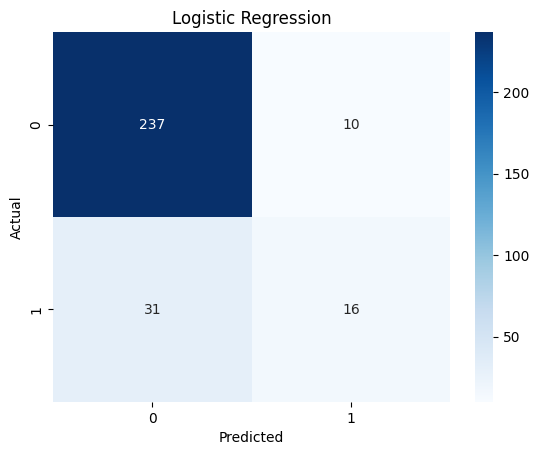

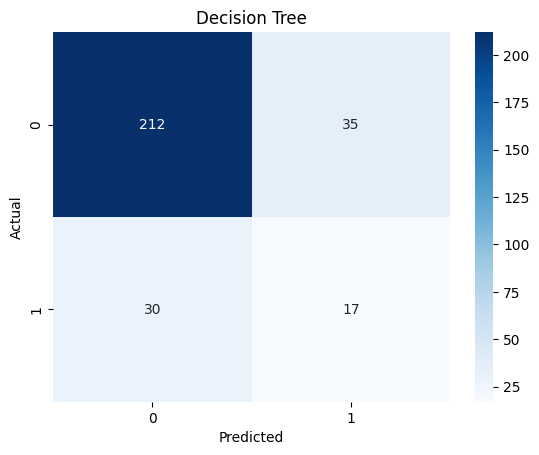

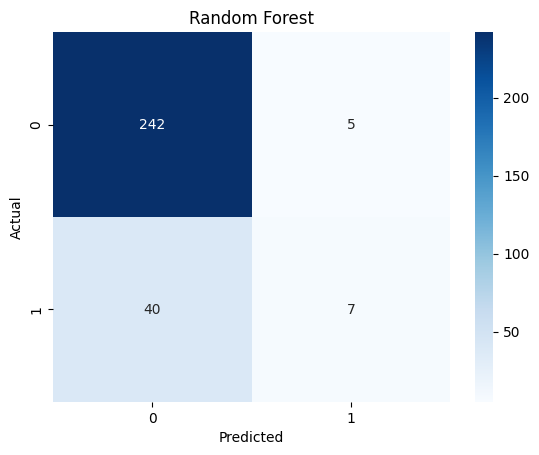

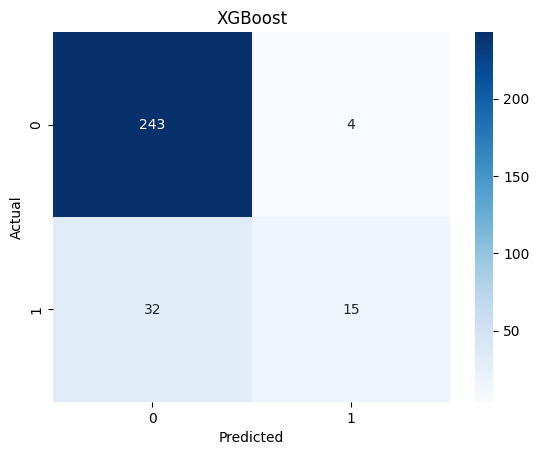

In [15]:
# STEP 13: CONFUSION MATRIX

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

for name, model in models.items():
    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


 Decision Tree


,0
num__TotalWorkingYears,0.116707
num__MonthlyIncome,0.091167
num__DailyRate,0.082756
num__Age,0.080267
num__HourlyRate,0.072862
num__NumCompaniesWorked,0.063384
cat__OverTime_Yes,0.044022
num__EmployeeNumber,0.036932
num__TrainingTimesLastYear,0.034046
num__YearsSinceLastPromotion,0.033755


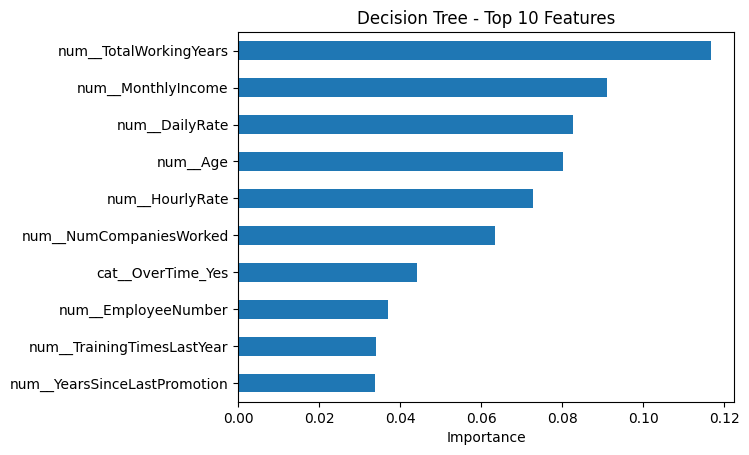


 Random Forest


,0
num__MonthlyIncome,0.066348
num__Age,0.060360
num__TotalWorkingYears,0.054729
num__DailyRate,0.046978
num__HourlyRate,0.044487
num__MonthlyRate,0.044068
num__EmployeeNumber,0.043800
num__DistanceFromHome,0.042807
num__YearsAtCompany,0.040469
num__YearsWithCurrManager,0.036168


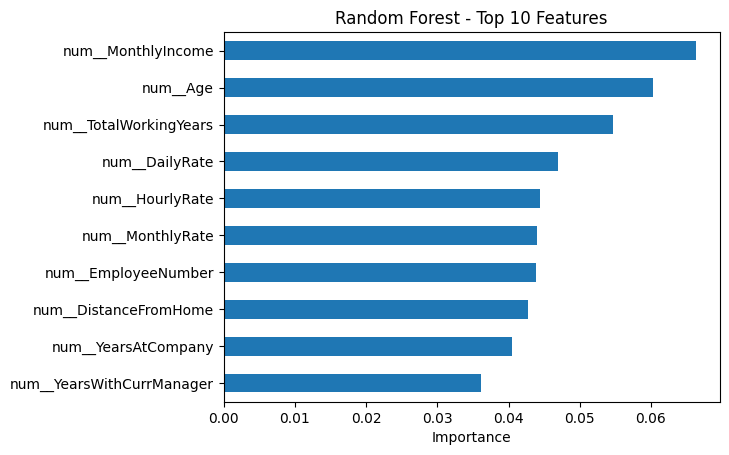


 XGBoost


,0
cat__MaritalStatus_Divorced,0.068575
num__TotalWorkingYears,0.062017
cat__OverTime_No,0.051775
cat__JobRole_Sales Executive,0.039406
num__YearsWithCurrManager,0.039362
num__StockOptionLevel,0.035724
num__YearsInCurrentRole,0.034953
cat__JobRole_Research Scientist,0.032480
num__Age,0.030766
num__JobInvolvement,0.030632


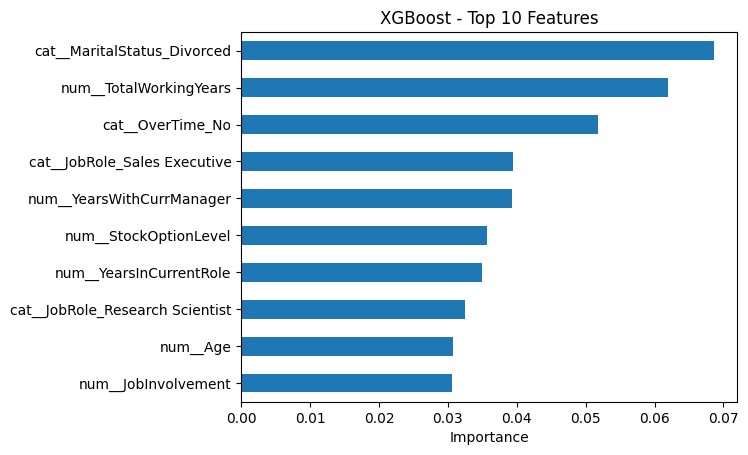

In [16]:
# STEP 14: FEATURE IMPORTANCE

import pandas as pd
import matplotlib.pyplot as plt

for name in ["Decision Tree", "Random Forest", "XGBoost"]:
    model = models[name]

    importance = pd.Series(
        model.feature_importances_,
        index=preprocessor.get_feature_names_out()
    ).sort_values(ascending=False).head(10)

    print("\n", name)
    display(importance)

    importance.sort_values().plot(kind="barh")
    plt.title(name + " - Top 10 Features")
    plt.xlabel("Importance")
    plt.show()

In [17]:
# STEP 15: MODEL COMPARISON

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_processed)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("F1 Score", ascending=False))

,Model,Accuracy,Precision,Recall,F1 Score
3,XGBoost,0.877551,0.789474,0.319149,0.454545
0,Logistic Regression,0.860544,0.615385,0.340426,0.438356
1,Decision Tree,0.778912,0.326923,0.361702,0.343434
2,Random Forest,0.846939,0.583333,0.148936,0.237288


In [18]:
# STEP 16: SAVE BEST MODEL

import joblib

best_model = models["XGBoost"]

joblib.dump(best_model, "employee_attrition_model.pkl")
joblib.dump(preprocessor, "employee_attrition_preprocessor.pkl")

print("Best Model Saved Successfully!")

Best Model Saved Successfully!


In [19]:
# STEP 17: DOWNLOAD MODEL FILES

from google.colab import files

files.download("employee_attrition_model.pkl")
files.download("employee_attrition_preprocessor.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# STEP 18: DOWNLOAD BOTH MODEL FILES

import zipfile
from google.colab import files

with zipfile.ZipFile("Employee_Attrition_Models.zip", "w") as zipf:
    zipf.write("employee_attrition_model.pkl")
    zipf.write("employee_attrition_preprocessor.pkl")

files.download("Employee_Attrition_Models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
from google.colab import files
files.download("Employee_Attrition_Models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# STEP 19: ROC-AUC EVALUATION

from sklearn.metrics import roc_auc_score

for name, model in models.items():
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    score = roc_auc_score(y_test, y_prob)

    print(name, "ROC-AUC:", round(score, 4))

Logistic Regression ROC-AUC: 0.8107
Decision Tree ROC-AUC: 0.61
Random Forest ROC-AUC: 0.8121
XGBoost ROC-AUC: 0.7721


In [25]:
# STEP 20: CROSS-VALIDATION

from sklearn.model_selection import cross_val_score

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_processed,
        y_train,
        cv=5,
        scoring="f1"
    )

    print(name)
    print("Cross-Validation F1:", round(scores.mean(), 4))

Logistic Regression
Cross-Validation F1: 0.5332
Decision Tree
Cross-Validation F1: 0.3389
Random Forest
Cross-Validation F1: 0.3137
XGBoost
Cross-Validation F1: 0.4242


In [26]:
# STEP 21: HYPERPARAMETER TUNING

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1:", round(grid_search.best_score_, 4))

Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best Cross-Validation F1: 0.3489


In [27]:
# STEP 22: TUNED MODEL EVALUATION

from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, roc_auc_score

best_rf_model = grid_search.best_estimator_

y_pred = best_rf_model.predict(X_test)
y_prob = best_rf_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Tuned Random Forest Results
Accuracy: 0.8503
Precision: 0.6364
Recall: 0.1489
F1 Score: 0.2414
ROC-AUC: 0.7924


In [28]:
# STEP 23: FINAL MODEL COMPARISON

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

y_pred = best_rf_model.predict(X_test)
y_prob = best_rf_model.predict_proba(X_test)[:, 1]

results.append({
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
})

comparison_df = pd.DataFrame(results)
display(comparison_df.round(4).sort_values("F1 Score", ascending=False))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,XGBoost,0.8776,0.7895,0.3191,0.4545,0.7721
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.8107
1,Decision Tree,0.7789,0.3269,0.3617,0.3434,0.6100
4,Tuned Random Forest,0.8503,0.6364,0.1489,0.2414,0.7924
2,Random Forest,0.8469,0.5833,0.1489,0.2373,0.8121


# Business Interpretation Report

## 1. Business Problem
Employee attrition occurs when employees leave an organization. High attrition increases recruitment costs, training expenses, and workload on existing employees. This project uses machine learning to predict employee attrition.

## 2. Dataset Overview
The IBM HR Analytics dataset contains 1,470 employee records and 35 columns. It includes employee details such as age, department, job role, salary, work experience, and overtime.

- Employees who stayed: 1,233
- Employees who left: 237
- Attrition rate: 16.12%

## 3. Model Performance
Four classification algorithms were evaluated: Logistic Regression, Decision Tree, Random Forest, and XGBoost. A tuned Random Forest model was also evaluated.

XGBoost achieved the highest test accuracy of 87.76% and F1-score of 45.45%. Logistic Regression achieved the highest recall among the original models at 34.04%.

## 4. Important Features
Feature importance analysis highlighted variables such as TotalWorkingYears, OverTime, Age, MaritalStatus, and YearsWithCurrManager.

These features may help identify patterns associated with employee attrition. Feature importance does not prove that a feature causes employees to leave.

## 5. Business Recommendations
- Monitor employees with frequent overtime.
- Review employee satisfaction and workload.
- Improve career growth and promotion opportunities.
- Conduct regular employee feedback surveys.
- Use prediction results to support HR decisions, not as the sole basis for them.

## 6. Conclusion
The project demonstrates how machine learning can support employee attrition analysis. XGBoost achieved the strongest overall test F1-score among the evaluated models. Further improvement in recall is needed to identify more employees who may leave.


# Model Evaluation Report

## 1. Introduction
This project evaluates machine learning classification models for predicting employee attrition using the IBM HR Analytics dataset.

## 2. Models Evaluated
The following models were trained and tested:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- Tuned Random Forest

## 3. Evaluation Metrics
The models were evaluated using:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

## 4. Model Performance

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| XGBoost | 87.76% | 78.95% | 31.91% | 45.45% | 77.21% |
| Logistic Regression | 86.05% | 61.54% | 34.04% | 43.84% | 81.07% |
| Decision Tree | 77.89% | 32.69% | 36.17% | 34.34% | 61.00% |
| Tuned Random Forest | 85.03% | 63.64% | 14.89% | 24.14% | 79.24% |
| Random Forest | 84.69% | 58.33% | 14.89% | 23.73% | 81.21% |

## 5. Hyperparameter Tuning
Random Forest was tuned using GridSearchCV with five-fold stratified cross-validation.

Best parameters:
- Number of estimators: 200
- Maximum depth: 10
- Minimum samples split: 2

Best cross-validation F1-score: 0.3489.

## 6. Final Result
XGBoost achieved the highest test accuracy (87.76%), precision (78.95%), and F1-score (45.45%). Logistic Regression achieved the highest recall among the original models (34.04%). Random Forest achieved the highest ROC-AUC (81.21%).

## 7. Conclusion
XGBoost showed the strongest overall performance based on the test F1-score. However, all models have scope for improvement, especially in recall. Further work can focus on class imbalance and improving the detection of employees likely to leave.